In [4]:
#Anggota Kelompok 15:
#Jyesthaputri Laksita W(110)
#Nur Adzlina (220)

###**Unsupervised: KMeans**

In [5]:
import pandas as pd
import pickle
from scipy.sparse import load_npz
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.metrics import silhouette_score

In [6]:
# Load CSV yang berisi komentar yang sudah di preproses, matriks TF-IDF, dan TF-IDF vectorizer

df = pd.read_csv('data_preprocessed.csv')       # Load CSV komentar bersih

d_FE = load_npz('d_FE_matrix.npz')              # Load matriks TF-IDF (d_FE)

with open('tfidf_vectorizer.pkl', 'rb') as f:   # Load vectorizer
    vectorizer_tfidf = pickle.load(f)
print("Data & Matriks TF-IDF Berhasil Dimuat!")
print("Jumlah Sampel Data:", len(df))
print("Kolom DataFrame:", df.columns.tolist())

Data & Matriks TF-IDF Berhasil Dimuat!
Jumlah Sampel Data: 112
Kolom DataFrame: ['authorId', 'text', '9_stemming']


k = 1 | Inertia = 108.4503
k = 2 | Inertia = 106.6794
k = 3 | Inertia = 103.8502
k = 4 | Inertia = 99.3647
k = 5 | Inertia = 97.9946
k = 6 | Inertia = 95.7125


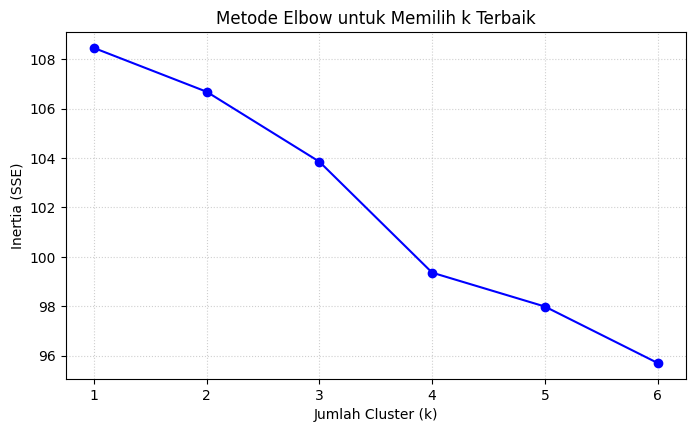

In [7]:
# Menentukan k terbaik menggunakan elbow-method

k_range = range(1, 7) # Rentang k=1 hingga k=6
inertia = []

 # Looping K-Means
for k in k_range:
    km_model = KMeans(n_clusters=k, random_state=10)
    km_model.fit(d_FE)
    inertia.append(km_model.inertia_)

# Hasil kuantitatif Inertia dari k=i
for k, val in zip(k_range, inertia):
    print(f"k = {k} | Inertia = {val:.4f}")

# Visualisasi Grafik Elbow
plt.figure(figsize=(8, 4.5))
plt.plot(k_range, inertia, marker="o", color="b", linestyle="-")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia (SSE)")
plt.title("Metode Elbow untuk Memilih k Terbaik")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

####Berdasarkan hasil pengujian k-means didapat titik elbow k=4, sehingga k terbaik yang digunakan adalah k=4

In [8]:
# Silhoutte Score

k_range_silhouette = range(2, 7) # Mentukan rentang cluster untuk pengujian Silhouette (k=2 sampai k=6)

print("--- Hasil Evaluasi Silhouette Score ---")

# Looping pengujian nilai Silhouette Score
for k in k_range_silhouette:
    km_model = KMeans(n_clusters=k, random_state=10)
    km_model.fit(d_FE)

    # Hitung nilai Silhouette Score
    score = silhouette_score(d_FE, km_model.labels_, metric='euclidean')
    print(f"Untuk k = {k}, Silhouette Score = {score:.4f}")

--- Hasil Evaluasi Silhouette Score ---
Untuk k = 2, Silhouette Score = 0.0124
Untuk k = 3, Silhouette Score = 0.0315
Untuk k = 4, Silhouette Score = 0.0473
Untuk k = 5, Silhouette Score = 0.0380
Untuk k = 6, Silhouette Score = 0.0445


In [9]:
# Penentuan sebaran data pada tiap cluster
n_clusters = 4      # dipilih k=4 hasil dari elbow-method dan silhoutte score

kM = KMeans(n_clusters=n_clusters, random_state=10).fit(d_FE)

# Memasukkan label cluster ke DataFrame
df['Kmeans_label'] = kM.labels_

# Sebaran jumlah data di tiap cluster
print("Jumlah komentar tiap cluster:")
print(df['Kmeans_label'].value_counts())
display(df.head())

Jumlah komentar tiap cluster:
Kmeans_label
1    69
3    27
0    12
2     4
Name: count, dtype: int64


,authorId,text,9_stemming,Kmeans_label
0,39555265659,dan tidak ada yang bertanggung jawab atas karh...,tidakada tanggungjawab,0
1,54145815667,Hancur bgt hati liat hutan segundul itu💔,hancur hati hutan gundul,1
2,3231696612,"Cocok ditanam SAWIT, kata mereka yang membakar...",cocok tanam sawit bakar,3
3,7803187840,Tuhan beri keajaiban utk Indonesia ❤️,ajaib,1
4,8271017,"Please jangan disingkat jadi “karhutla”, kita ...",singkat sebut hutan lahan genting rasa,1


=== K-Means WordCloud untuk Cluster 0 ===


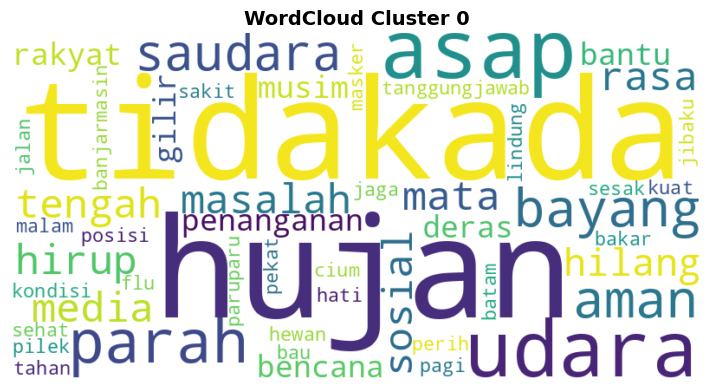



=== K-Means WordCloud untuk Cluster 1 ===


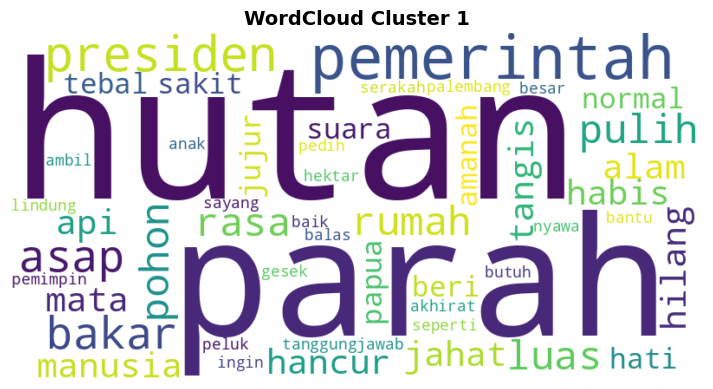



=== K-Means WordCloud untuk Cluster 2 ===


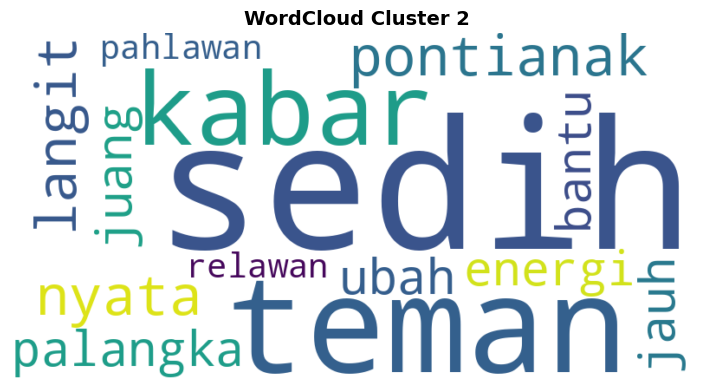



=== K-Means WordCloud untuk Cluster 3 ===


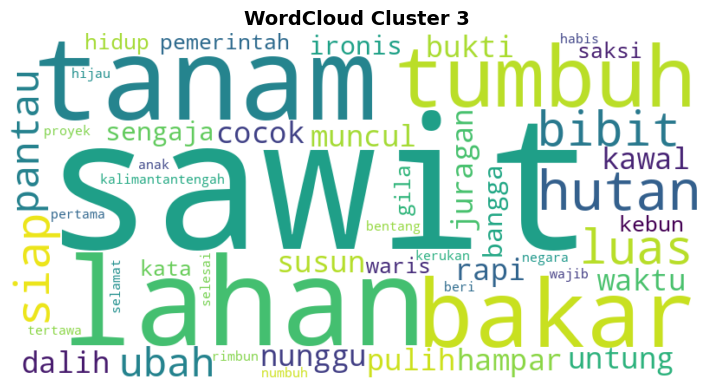

In [10]:
# Loop otomatis untuk 4 cluster (Cluster 0, 1, 2,3)
for c in range(4):
    print(f"=== K-Means WordCloud untuk Cluster {c} ===")

    # Filter DataFrame per cluster
    df_c = df[df['Kmeans_label'] == c]

    # Ambil kata dari kolom '9_stemming'
    long_string = " ".join(df_c['9_stemming'].dropna().astype(str))

    # Generate WordCloud
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        max_words=50
    ).generate(long_string)

    # Hasil WordCloud
    plt.figure(figsize=(9, 4.5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'WordCloud Cluster {c}', fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()
    print("\n")

###**Unsupervised: Hierarchical**

In [11]:
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

In [12]:
# Uji Silhoutte Score (hierarchical clustering/ward linkage)
df = pd.read_csv('data_preprocessed.csv')
vectorizer = TfidfVectorizer()
d_FE_dense = vectorizer.fit_transform(df['9_stemming'].dropna()).toarray()

print("=== Silhouette Score Hierarchical Clustering (Ward Linkage) ===")

k_range = range(2, 7) # rentang uji k=2 hingga k=6

for k in k_range:
    # Inisialisasi model Hierarchical Agglomerative Clustering
    hac_model = AgglomerativeClustering(
        n_clusters=k, metric='euclidean', linkage='ward'
    )

    # Fit dan dapatkan label cluster
    ward_labels = hac_model.fit_predict(d_FE_dense)

    # Hitung nilai Silhouette Score
    score = silhouette_score(d_FE_dense, ward_labels, metric='euclidean')

    print(f"k = {k} | Silhouette Score (Ward) = {score:.4f}")

=== Silhouette Score Hierarchical Clustering (Ward Linkage) ===
k = 2 | Silhouette Score (Ward) = 0.0267
k = 3 | Silhouette Score (Ward) = 0.0520
k = 4 | Silhouette Score (Ward) = 0.0537
k = 5 | Silhouette Score (Ward) = 0.0607
k = 6 | Silhouette Score (Ward) = 0.0669


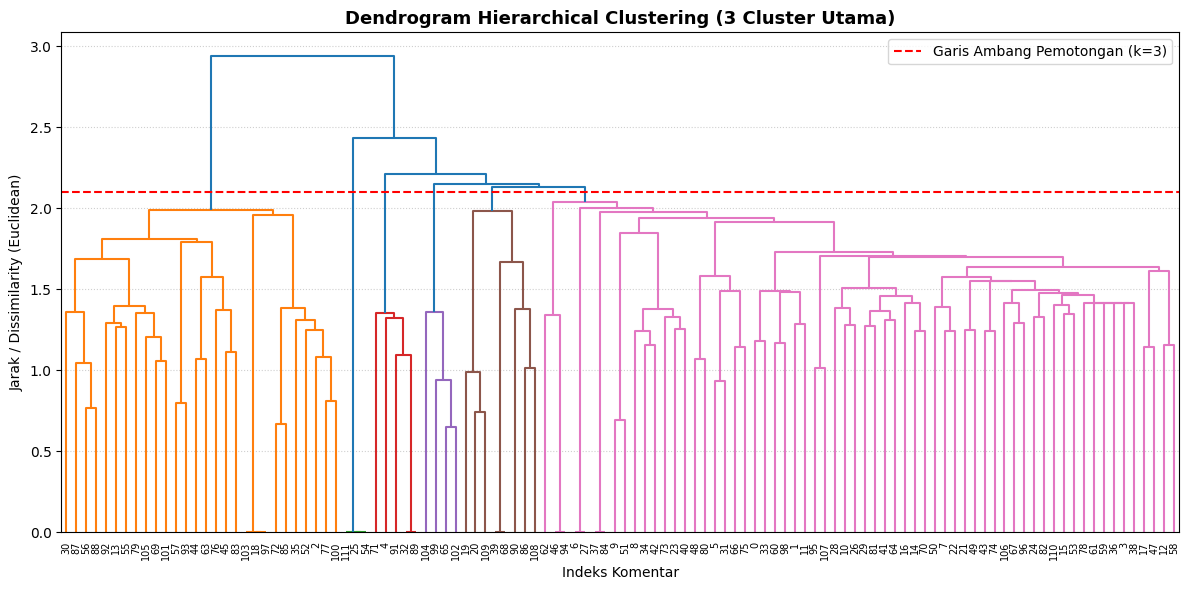

Daftar Kolom: ['authorId', 'text', '9_stemming', 'Ward_label']


,text,9_stemming,Ward_label
0,dan tidak ada yang bertanggung jawab atas karh...,tidakada tanggungjawab,0
1,Hancur bgt hati liat hutan segundul itu💔,hancur hati hutan gundul,0
2,"Cocok ditanam SAWIT, kata mereka yang membakar...",cocok tanam sawit bakar,1
3,Tuhan beri keajaiban utk Indonesia ❤️,ajaib,0
4,"Please jangan disingkat jadi “karhutla”, kita ...",singkat sebut hutan lahan genting rasa,0
5,🐷 : “TIDAK SEPARAH DI MEDSOS”,parah mediasosial,0
6,"Siapa yg bilang, sudah 'NORMAL'???! 😡😡",normal,0
7,Pak @prabowo ada tindakan biar masalah ini kel...,tindak masalah selesai jujur mahasiswa negeri ...,0
8,Pemerintah sedang mem-black campaign dirinya s...,pemerintah kampanyehitam diri,0
9,terimakasih sdh bersuara❤️😢,suara,0


In [13]:
# Visualisasi Dendogram dan Penambahan Kolom Ward Label
# Fit & Predict Hierarchical Clustering / WARD (k=3)
ward_model = AgglomerativeClustering(
    n_clusters=3, metric='euclidean', linkage='ward'
)
df['Ward_label'] = ward_model.fit_predict(d_FE_dense)

# Visualisasi Dendogram (Konsisten k=3 pada y=2.1)
linkage_data = linkage(d_FE_dense, method='ward', metric='euclidean')

plt.figure(figsize=(12, 6))
dendrogram(
    linkage_data,
    orientation='top',
    color_threshold=2.1,  # Memberikan pemisahan warna visual pada 3 dahan utama
    leaf_rotation=90,
    leaf_font_size=7,
)

plt.axhline(
    y=2.1, color='r', linestyle='--', label='Garis Ambang Pemotongan (k=3)'
)

plt.title(
    'Dendrogram Hierarchical Clustering (3 Cluster Utama)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Indeks Komentar', fontsize=10)
plt.ylabel('Jarak / Dissimilarity (Euclidean)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Hasil kolom DataFrame dengan Ward Label
print("Daftar Kolom:", df.columns.tolist())
display(df[['text', '9_stemming', 'Ward_label']].head(10))


In [14]:
# Klustering kata/data
n_clusters = 3

# Konversi d_FE ke dense array (Wajib jika menggunakan linkage='ward')
if hasattr(d_FE, 'toarray'):
    d_FE_dense = d_FE.toarray()
else:
    d_FE_dense = d_FE

# Inisialisasi & Fit Model Agglomerative Clustering
hierarchical_cluster = AgglomerativeClustering(
    n_clusters=n_clusters,
    metric='euclidean',
    linkage='ward'
)

# Melakukan prediksi dan langsung memasukkan hasilnya ke kolom 'Ward_label'
df['Ward_label'] = hierarchical_cluster.fit_predict(d_FE_dense)

# Tampilkan sebaran jumlah data di tiap cluster Ward
print("--- Sebaran Komentar per Cluster (Hierarchical Ward) ---")
print(df['Ward_label'].value_counts().sort_index())

# dataframe terbaru dengan ward label
display(df[['text', '9_stemming', 'Ward_label']].head(10))

--- Sebaran Komentar per Cluster (Hierarchical Ward) ---
Ward_label
0    81
1    28
2     3
Name: count, dtype: int64


,text,9_stemming,Ward_label
0,dan tidak ada yang bertanggung jawab atas karh...,tidakada tanggungjawab,0
1,Hancur bgt hati liat hutan segundul itu💔,hancur hati hutan gundul,0
2,"Cocok ditanam SAWIT, kata mereka yang membakar...",cocok tanam sawit bakar,1
3,Tuhan beri keajaiban utk Indonesia ❤️,ajaib,0
4,"Please jangan disingkat jadi “karhutla”, kita ...",singkat sebut hutan lahan genting rasa,0
5,🐷 : “TIDAK SEPARAH DI MEDSOS”,parah mediasosial,0
6,"Siapa yg bilang, sudah 'NORMAL'???! 😡😡",normal,0
7,Pak @prabowo ada tindakan biar masalah ini kel...,tindak masalah selesai jujur mahasiswa negeri ...,0
8,Pemerintah sedang mem-black campaign dirinya s...,pemerintah kampanyehitam diri,0
9,terimakasih sdh bersuara❤️😢,suara,0


=== WordCloud Hierarchical Clustering (Ward) - Cluster 0 ===


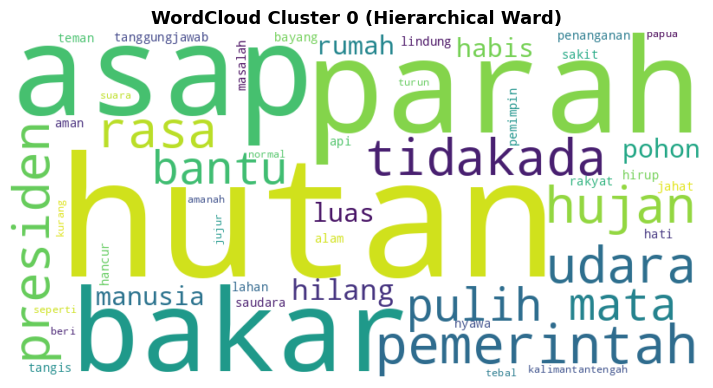



=== WordCloud Hierarchical Clustering (Ward) - Cluster 1 ===


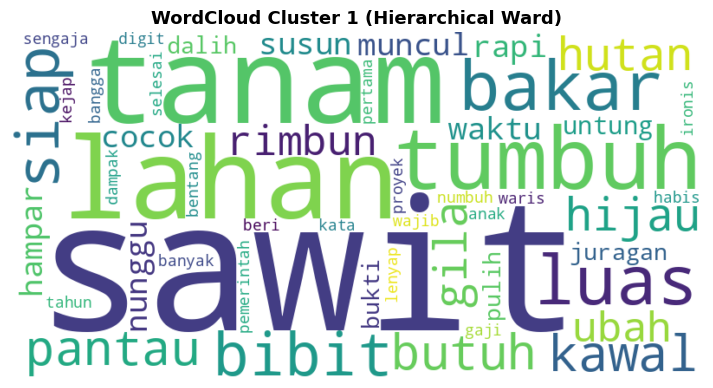



=== WordCloud Hierarchical Clustering (Ward) - Cluster 2 ===


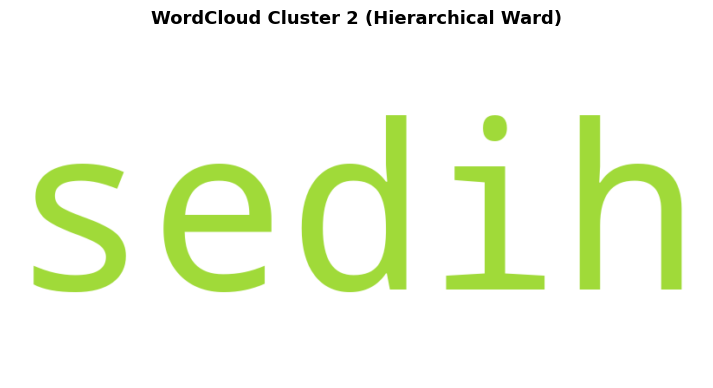

In [15]:
n_clusters = 3

for c in range(n_clusters):
    print(f"=== WordCloud Hierarchical Clustering (Ward) - Cluster {c} ===")

    # Filter DataFrame berdasarkan Ward_label
    df_c = df[df['Ward_label'] == c]

    long_string = " ".join(df_c['9_stemming'].dropna().astype(str))

    # Pengecekan kata yang valid di dalam cluster
    if len(long_string.strip()) > 0:
        # Inisialisasi WordCloud dengan parameter rapi
        wordcloud = WordCloud(
            width=800,
            height=400,
            background_color="white",
            max_words=50,  # Menampilkan 50 kata paling dominan per cluster
            contour_width=3,
        ).generate(long_string)

        # Visualisasi Gambar WordCloud
        plt.figure(figsize=(9, 4.5))
        plt.imshow(wordcloud, interpolation="bilinear")
        plt.title(
            f"WordCloud Cluster {c} (Hierarchical Ward)",
            fontsize=13,
            fontweight="bold",
        )
        plt.axis("off")
        plt.show()
        print("\n")
    else:
        print(
            f"Klaster {c} tidak memiliki teks yang cukup untuk membuat WordCloud.\n"
        )

###**Supervised: Classify/Klasifikasi**

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans

In [18]:
# Muat ulang DataFrame
df = pd.read_csv('data_preprocessed.csv')

# Vektorisasi awal menggunakan TF-IDF dari '9_stemming'
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['9_stemming'].dropna())

# Membuat kembali model KMeans (k=4) dan memasang labelnya ke df
km_model = KMeans(n_clusters=4, random_state=10)
df['Kmeans_label'] = km_model.fit_predict(X)

y = df['Kmeans_label']

# Pembagian Data Latih & Uji (70% Train, 30% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Pelatihan Model Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prediksi Data Uji & Evaluasi Performa Model
y_pred = rf_model.predict(X_test)

print("=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, zero_division=0))

=== CONFUSION MATRIX ===
[[ 0  4  0  0]
 [ 0 21  0  0]
 [ 0  0  1  0]
 [ 0  1  0  7]]

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.81      1.00      0.89        21
           2       1.00      1.00      1.00         1
           3       1.00      0.88      0.93         8

    accuracy                           0.85        34
   macro avg       0.70      0.72      0.71        34
weighted avg       0.76      0.85      0.80        34



In [25]:
# Prediksi Komentar Baru

teks_baru_raw = "pasti nanti ditanam sawit" # Komentar mentah baru

# Teks yang sudah di-preprocess/stemmed (sesuai kata kunci: sawit)
teks_baru_clean = "sawit"

# Transformasi menggunakan vectorizer yang sama
teks_vectorized = vectorizer.transform([teks_baru_clean])

# Prediksi Cluster
hasil_prediksi = rf_model.predict(teks_vectorized)[0]

print(f"Teks Asli: '{teks_baru_raw}'")
print(f"Hasil Prediksi Model -> Masuk ke Cluster: {hasil_prediksi}")

Teks Asli: 'pasti nanti ditanam sawit'
Hasil Prediksi Model -> Masuk ke Cluster: 3
